In [1]:
import json
from collections import Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
JSON_PATH = "../dataset/jobs_dataset.json"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    jobs = json.load(f)

print(f"Total jobs: {len(jobs):,}")

Total jobs: 30,601


In [3]:
counter = Counter()

for job in jobs:
    skills = job.get("skills", [])

    if not skills:
        continue

    for skill in skills:
        if skill:
            counter[skill.strip()] += 1

print(f"Unique Skills: {len(counter):,}")

Unique Skills: 435


In [4]:
df = (
    pd.DataFrame(
        counter.items(),
        columns=["Skill", "Frequency"]
    )
    .sort_values("Frequency", ascending=False)
    .reset_index(drop=True)
)

df.head(20)

,Skill,Frequency
0,ventas,7325
1,excel,5273
2,limpieza,3906
3,office,3216
4,inventario,2745
5,alimentos,2429
6,proveedores,2318
7,contabilidad,2312
8,call center,1993
9,despacho,1957


In [5]:
df.to_csv(
    "../dataset/skills_frequency.csv",
    index=False,
    encoding="utf-8-sig"
)

print("CSV exported")

CSV exported


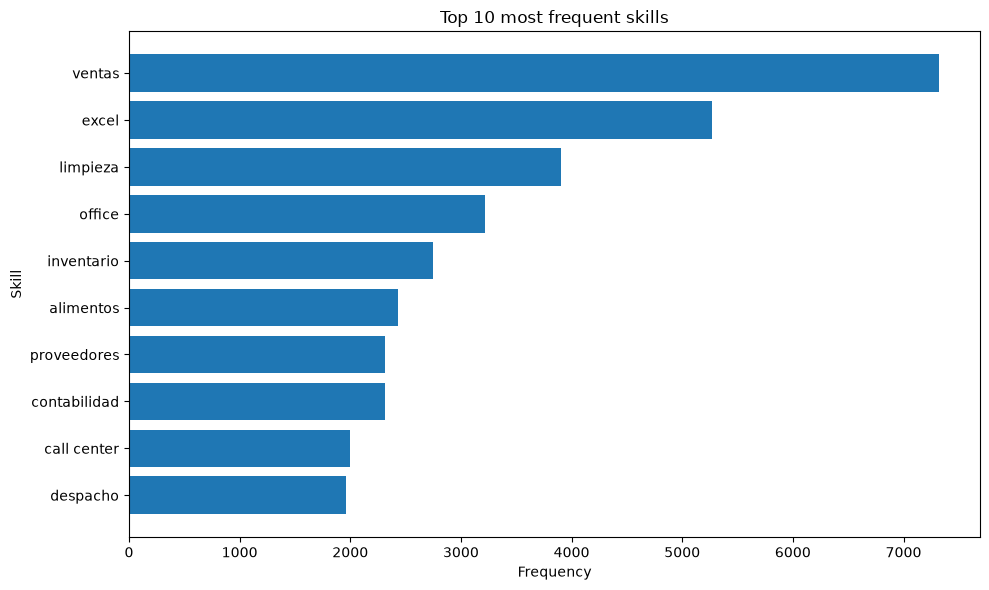

In [6]:
TOP = 10

top = df.head(TOP)

plt.figure(figsize=(10,6))

plt.barh(top["Skill"][::-1], top["Frequency"][::-1])

plt.xlabel("Frequency")
plt.ylabel("Skill")
plt.title(f"Top {TOP} most frequent skills")

plt.tight_layout()
plt.show()

In [7]:
jobs_with_skills = sum(1 for job in jobs if job.get("skills"))

total_skills = sum(counter.values())

avg_skills = total_skills / jobs_with_skills

print(f"Jobs with skills    : {jobs_with_skills:,}")
print(f"Skills extracted    : {total_skills:,}")
print(f"Unique skills       : {len(counter):,}")
print(f"Average per job     : {avg_skills:.2f}")

Jobs with skills    : 26,673
Skills extracted    : 79,104
Unique skills       : 435
Average per job     : 2.97
